# Klasifikasi Gambar Sampah dengan EfficientNet-B3

Notebook ini menggunakan EfficientNet-B3 dengan transfer learning untuk mengklasifikasikan gambar sampah ke dalam 5 kelas pada dataset **Dataset Mahasiswa** (Kaggle: `ferntanyl/dataset-mahasiswa`).

## Dataset
- Folder `train/` berisi 5 kelas: `botol_plastik`, `gelas_plastik`, `kertas_kardus`, `saset_kemasan`, dan `styrofoam`
- File label: `train_sources.csv`
- Karena hanya folder `train` yang berlabel, data dibagi menjadi **80% training** dan **20% validasi** (stratified) untuk evaluasi.

## Latar Belakang
EfficientNet-B3 adalah arsitektur jaringan saraf yang dioptimalkan untuk klasifikasi gambar. 300 Gecs menggunakan transfer learning dengan bobot pre-trained dari ImageNet untuk memanfaatkan fitur-fitur yang telah dipelajari sebelumnya.

## Environment
venv (python 3.11.9)

## Anggota kelompok
- Muhammad Nelwan Fakhri (122140173)
- Ali Akbar   (123140162)
- Raditya Erza Farandi   (122140209)

## 1. Import Library yang Dibutuhkan

Kita menggunakan:
- PyTorch: Framework deep learning utama
- torchvision: Untuk model EfficientNet dan transformasi gambar
- OpenCV (cv2): Untuk pemrosesan gambar
- tqdm: Untuk pelacakan progres
- scikit-learn: Untuk pembagian data dan metrik evaluasi
- matplotlib & seaborn: Untuk visualisasi

Kita juga mengatur seed acak agar hasil dapat direproduksi.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
from torchvision.transforms import (ToTensor, Normalize, Compose, ToPILImage,
                                    RandomHorizontalFlip, RandomRotation, ColorJitter)
import cv2
import os
import random
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import seaborn as sns
from itertools import cycle

# Set random seed for reproducibility
RANDOM_SEED = 2025
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Utility function for device setup
def check_set_gpu(override=None):
    if override == None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
            print(f"Using GPU: {torch.cuda.get_device_name(0)}")
        elif torch.backends.mps.is_available():
            device = torch.device('mps')
            print(f"Using MPS: {torch.backends.mps.is_available()}")
        else:
            device = torch.device('cpu')
            print(f"Using CPU: {torch.device('cpu')}")
    else:
        device = torch.device(override)
    return device

# Set device
device = check_set_gpu()

Using GPU: Tesla T4


## 2. Lokasi Dataset dan Pembacaan `train_sources.csv`

Dataset diunduh dari Kaggle: https://www.kaggle.com/datasets/ferntanyl/dataset-mahasiswa

Cara mendapatkan dataset:
- **Kaggle Notebook**: tambahkan dataset lewat *Add Input*, otomatis tersedia di `/kaggle/input/...`
- **Lokal**: unduh zip dari Kaggle lalu ekstrak, atau gunakan `kagglehub` (baris yang di-comment di bawah)

Sel di bawah mencari `train_sources.csv` dan folder `train/` secara otomatis. Jika gagal, isi `DATA_ROOT` (atau `TRAIN_DIR` dan `CSV_PATH`) secara manual.

In [2]:
# ====== KONFIGURASI DATASET ======
# Opsi: download otomatis via kagglehub (pip install kagglehub), lalu uncomment:
# import kagglehub
# DATA_ROOT = kagglehub.dataset_download("ferntanyl/dataset-mahasiswa")

DATA_ROOT = '/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train'
TRAIN_DIR = DATA_ROOT
CSV_PATH = os.path.join(os.path.dirname(DATA_ROOT), 'train_sources.csv')

# Jika nama kolom pada CSV tidak terdeteksi otomatis, isi manual di sini
FILENAME_COL = None   # contoh: 'filename'
LABEL_COL    = None   # contoh: 'label'
USE_FOLDER_AS_LABEL = False  # True = abaikan label CSV, pakai nama folder kelas

SEARCH_ROOTS = [DATA_ROOT] if DATA_ROOT else ['.', '/kaggle/input']

def find_dataset(roots, max_depth=5):
    csv_found, train_found = None, None
    for root in roots:
        if not root or not os.path.isdir(root):
            continue
        base_depth = root.rstrip(os.sep).count(os.sep)
        for dirpath, dirnames, filenames in os.walk(root):
            if dirpath.count(os.sep) - base_depth >= max_depth:
                dirnames[:] = []
                continue
            if csv_found is None and 'train_sources.csv' in filenames:
                csv_found = os.path.join(dirpath, 'train_sources.csv')
            if train_found is None and 'train' in dirnames:
                cand = os.path.join(dirpath, 'train')
                subdirs = [d for d in os.listdir(cand) if os.path.isdir(os.path.join(cand, d))]
                if len(subdirs) >= 2:   # folder train berisi subfolder kelas
                    train_found = cand
    return train_found, csv_found

if TRAIN_DIR is None or CSV_PATH is None:
    _train, _csv = find_dataset(SEARCH_ROOTS)
    TRAIN_DIR = TRAIN_DIR or _train
    CSV_PATH = CSV_PATH or _csv

assert TRAIN_DIR and os.path.isdir(TRAIN_DIR), "Folder train tidak ditemukan. Isi DATA_ROOT / TRAIN_DIR secara manual."
assert CSV_PATH and os.path.isfile(CSV_PATH), "train_sources.csv tidak ditemukan. Isi CSV_PATH secara manual."
if DATA_ROOT is None:
    DATA_ROOT = os.path.dirname(TRAIN_DIR)

print("TRAIN_DIR :", TRAIN_DIR)
print("CSV_PATH  :", CSV_PATH)

# Daftar kelas berdasarkan nama folder
class_folders = sorted(d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d)))
print("\nFolder kelas :", class_folders)
for c in class_folders:
    n = len([f for f in os.listdir(os.path.join(TRAIN_DIR, c))])
    print(f"  - {c}: {n} file")

TRAIN_DIR : /kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train
CSV_PATH  : /kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train_sources.csv

Folder kelas : ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
  - botol_plastik: 523 file
  - gelas_plastik: 521 file
  - kertas_kardus: 365 file
  - saset_kemasan: 673 file
  - styrofoam: 671 file


In [3]:
# Baca train_sources.csv
df = pd.read_csv(CSV_PATH)
print("Ukuran CSV :", df.shape)
print("Kolom      :", df.columns.tolist())
display(df.head())

FILE_CANDIDATES  = ['filename', 'file_name', 'file', 'image', 'image_name', 'img', 'image_path', 'filepath', 'path', 'id']
LABEL_CANDIDATES = ['label', 'labels', 'class', 'kelas', 'category', 'target']

def pick_col(candidates, columns):
    lower = {c.lower(): c for c in columns}
    for cand in candidates:
        if cand in lower:
            return lower[cand]
    return None

if FILENAME_COL is None:
    FILENAME_COL = pick_col(FILE_CANDIDATES, df.columns) or df.columns[0]
if LABEL_COL is None and not USE_FOLDER_AS_LABEL:
    LABEL_COL = pick_col(LABEL_CANDIDATES, df.columns)
    if LABEL_COL is None:
        print("Kolom label tidak terdeteksi -> memakai nama folder sebagai label.")
        USE_FOLDER_AS_LABEL = True

print("\nKolom nama file :", FILENAME_COL)
print("Kolom label     :", 'nama folder' if USE_FOLDER_AS_LABEL else LABEL_COL)
if not USE_FOLDER_AS_LABEL:
    print("\nDistribusi label di CSV:")
    print(df[LABEL_COL].value_counts())

Ukuran CSV : (2964, 5)
Kolom      : ['file', 'label', 'image_url', 'page_url', 'title']


,file,label,image_url,page_url,title
0,botol_plastik/botol_plastik_05fc6c40ece8fcd4.jpg,botol_plastik,https://topbotolpusat.com/wp-content/uploads/2...,https://topbotolpusat.com/kemasan-botol-plastik/,Jual Kemasan Botol Plastik: Tersedia Berbagai ...
1,botol_plastik/botol_plastik_4f1d3db585e4c9e6.jpg,botol_plastik,https://lzd-img-global.slatic.net/g/p/62302097...,https://www.lazada.co.id/products/botol-plasti...,Botol Plastik Putih PS 500 ml / Botol Kosong M...
2,botol_plastik/botol_plastik_cf171a36ed4faf7f.jpg,botol_plastik,https://down-id.img.susercontent.com/file/id-1...,https://shopee.co.id/Air-Mineral-botol-kecil-2...,Jual Air Mineral botol kecil 220 ml merk ozoni...
3,botol_plastik/botol_plastik_85c4868d185357a2.jpg,botol_plastik,https://images.pexels.com/photos/7767788/pexel...,https://www.pexels.com/photo/plastic-bottles-i...,Plastic Bottles in Close Up Shot · Free Stock ...
4,botol_plastik/botol_plastik_79fab9087d507575.jpg,botol_plastik,https://img.antarafoto.com/cache/1200x798/2024...,https://www.antarafoto.com/id/view/2139903/sam...,Sampah plastik terbanyak di Indonesia | ANTARA...



Kolom nama file : file
Kolom label     : label

Distribusi label di CSV:
label
saset_kemasan    758
styrofoam        698
gelas_plastik    572
botol_plastik    541
kertas_kardus    395
Name: count, dtype: int64


In [4]:
# Cocokkan nama file di CSV dengan path gambar sebenarnya di folder train
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

image_index = {}   # nama file -> daftar path (bisa lebih dari satu jika nama sama di beberapa folder)
for dp, _, fs in os.walk(TRAIN_DIR):
    for f in fs:
        if f.lower().endswith(IMG_EXT):
            image_index.setdefault(f, []).append(os.path.join(dp, f))
print("Total gambar ditemukan di folder train:", sum(len(v) for v in image_index.values()))

def norm(s):
    return str(s).strip().lower().replace(' ', '_').replace('-', '_')

def resolve_path(fname, label=None):
    fname = str(fname).strip()
    for base in (TRAIN_DIR, DATA_ROOT, os.path.dirname(CSV_PATH)):
        p = os.path.join(base, fname)
        if os.path.isfile(p):
            return p
    matches = image_index.get(os.path.basename(fname), [])
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1 and label is not None:
        for m in matches:
            if norm(os.path.basename(os.path.dirname(m))) == norm(label):
                return m
    return matches[0] if matches else None

samples, missing = [], []
for _, row in df.iterrows():
    lbl_csv = None if USE_FOLDER_AS_LABEL else row[LABEL_COL]
    path = resolve_path(row[FILENAME_COL], lbl_csv)
    if path is None:
        missing.append(row[FILENAME_COL])
        continue
    label = os.path.basename(os.path.dirname(path)) if USE_FOLDER_AS_LABEL else str(lbl_csv).strip()
    samples.append((path, label))

print(f"Sampel valid : {len(samples)}")
print(f"File hilang  : {len(missing)}", missing[:5])
assert len(samples) > 0, "Tidak ada gambar yang cocok dengan CSV. Periksa FILENAME_COL / struktur folder."

# Bagi data: 80% training, 20% validasi (stratified)
paths_all  = [s[0] for s in samples]
labels_all = [s[1] for s in samples]
train_idx, val_idx = train_test_split(
    np.arange(len(samples)), test_size=0.2, stratify=labels_all, random_state=RANDOM_SEED
)
train_samples = [samples[i] for i in train_idx]
val_samples   = [samples[i] for i in val_idx]
print(f"Train: {len(train_samples)} | Validasi: {len(val_samples)}")

Total gambar ditemukan di folder train: 2753
Sampel valid : 2753
File hilang  : 211 ['botol_plastik/botol_plastik_26d5e6b09f0909ee.jpg', 'botol_plastik/botol_plastik_dbfe7757a91a5fdd.jpg', 'botol_plastik/botol_plastik_62f43182e82e55f9.jpg', 'botol_plastik/botol_plastik_8f9490739789340f.jpg', 'botol_plastik/botol_plastik_da43d0513e62afcf.jpg']
Train: 2202 | Validasi: 551


## 3. Implementasi Dataset

Kelas `DatasetSampah` merupakan turunan dari `torch.utils.data.Dataset`. Kelas ini akan:

- Memuat gambar berdasarkan daftar `(path, label)` hasil pembacaan `train_sources.csv`
- Mengubah ukuran gambar menjadi 300x300 dan konversi BGR ke RGB
- Menerapkan augmentasi (flip, rotasi, color jitter) hanya pada data training
- Normalisasi menggunakan statistik ImageNet
- Mengembalikan `(gambar, label, path)`

In [5]:
class DatasetSampah(Dataset):
    # normalisasi ImageNet
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD = [0.229, 0.224, 0.225]

    def __init__(self, samples, img_size=(300, 300), train=False):
        self.samples = samples          # list of (path, label)
        self.img_size = img_size
        self.train = train

        if train:
            self.transform = Compose([
                ToPILImage(),
                RandomHorizontalFlip(),
                RandomRotation(15),
                ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
                ToTensor(),
                Normalize(mean=self.IMAGENET_MEAN, std=self.IMAGENET_STD)
            ])
        else:
            self.transform = Compose([
                ToTensor(),
                Normalize(mean=self.IMAGENET_MEAN, std=self.IMAGENET_STD)
            ])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = cv2.imread(img_path)
        if image is None:
            raise ValueError(f"Cannot read image: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, self.img_size)
        image = self.transform(image)
        return image, label, img_path

# fungsi label encoding
def create_label_encoder(dataset):
    # Buat mapping label string -> indeks numerik (tanpa membuka gambar)
    all_labels = [label for _, label in dataset.samples]
    unique_labels = sorted(set(all_labels))
    label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}
    idx_to_label = {idx: label for idx, label in enumerate(unique_labels)}
    return label_to_idx, idx_to_label, unique_labels

## 4. Fungsi-fungsi Pelatihan

### Fungsi train_one_epoch:
- Melatih model untuk satu epoch
- Menghitung loss dan akurasi training
- Melakukan optimisasi parameter model

### Fungsi validate:
- Mengevaluasi model pada data validasi
- Menghitung loss dan akurasi validasi
- Tidak melakukan backpropagation

Label string dikonversi ke indeks numerik, dan progres ditampilkan dengan tqdm.

In [6]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, label_to_idx):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    pbar = tqdm(dataloader, desc='Training')
    for batch_idx, (inputs, labels_tuple, _) in enumerate(pbar):
        inputs = inputs.to(device)

        # mengubah label string ke indeks numerik
        label_indices = [label_to_idx[label] for label in labels_tuple]
        targets = torch.tensor(label_indices, dtype=torch.long).to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        pbar.set_postfix({
            'loss': total_loss/(batch_idx+1),
            'acc': 100.*correct/total
        })

    return total_loss/len(dataloader), 100.*correct/total

def validate(model, dataloader, criterion, device, label_to_idx):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        pbar = tqdm(dataloader, desc='Validation')
        for batch_idx, (inputs, labels_tuple, _) in enumerate(pbar):
            inputs = inputs.to(device)

            label_indices = [label_to_idx[label] for label in labels_tuple]
            targets = torch.tensor(label_indices, dtype=torch.long).to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            pbar.set_postfix({
                'loss': total_loss/(batch_idx+1),
                'acc': 100.*correct/total
            })

    return total_loss/len(dataloader), 100.*correct/total

## 5. Persiapan Dataset dan DataLoader

1. **Hyperparameter**: epoch, ukuran batch, learning rate, ukuran gambar 300x300
2. **Dataset**: training (dengan augmentasi) dan validasi
3. **Pengkodean Label**: mapping dua arah (indeks ↔ label) dari 5 kelas
4. **DataLoader**: shuffle untuk data training

In [7]:
# Hyperparameter
num_epochs = 15
batch_size = 32
learning_rate = 1e-3
img_size = (300, 300)  # EfficientNet-B3 input size

train_dataset = DatasetSampah(train_samples, img_size=img_size, train=True)
val_dataset   = DatasetSampah(val_samples,   img_size=img_size, train=False)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Val dataset size  : {len(val_dataset)}")

# Label encoding dari seluruh data (supaya konsisten antara train dan val)
full_dataset = DatasetSampah(samples, img_size=img_size, train=False)
label_to_idx, idx_to_label, unique_labels = create_label_encoder(full_dataset)
num_classes = len(unique_labels)

print(f"\nNumber of classes: {num_classes}")
print(f"Classes found    : {unique_labels}")
print(f"Label to index   : {label_to_idx}")

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=0, pin_memory=(device.type == 'cuda'))
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                        num_workers=0, pin_memory=(device.type == 'cuda'))
print("\nDataset and DataLoader created successfully!")

Train dataset size: 2202
Val dataset size  : 551

Number of classes: 5
Classes found    : ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
Label to index   : {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}

Dataset and DataLoader created successfully!


## Debug Pemuatan Dataset

Uji pemuatan dataset untuk memastikan:
- Path gambar valid
- Bentuk tensor dan label sesuai
- Satu batch dapat dimuat dengan benar

In [8]:
print("Testing dataset loading...")
try:
    for i in range(min(5, len(train_dataset))):
        image, label, path = train_dataset[i]
        print(f"Sample {i+1}: shape={tuple(image.shape)} | label={label} | path={path}")

    images, labels, paths = next(iter(train_loader))
    print("\nSuccessfully loaded a batch:")
    print(f"- Batch image shape: {images.shape}")
    print(f"- Labels (first 8): {list(labels[:8])}")
    print(f"- Image tensor range: [{images.min():.3f}, {images.max():.3f}]")
    print(f"- Image tensor mean: {images.mean():.3f} | std: {images.std():.3f}")
except Exception as e:
    print(f"Full error: {e.__class__.__name__}: {str(e)}")
    raise

Testing dataset loading...
Sample 1: shape=(3, 300, 300) | label=saset_kemasan | path=/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train/saset_kemasan/saset_kemasan_83d7e669108dbf62.jpg
Sample 2: shape=(3, 300, 300) | label=gelas_plastik | path=/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train/gelas_plastik/gelas_plastik_76fc9f8b944c3c7e.jpg
Sample 3: shape=(3, 300, 300) | label=styrofoam | path=/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train/styrofoam/styrofoam_e83d4e7e7f008cf8.jpg
Sample 4: shape=(3, 300, 300) | label=styrofoam | path=/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train/styrofoam/styrofoam_c5daca7ee7f2461c.jpg
Sample 5: shape=(3, 300, 300) | label=gelas_plastik | path=/kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train/gelas_plastik/gelas_plastik_b8425223fd2bd3ee.jpg

Successfully loaded a batch:
- Batch image shape: torch.Size([32, 3, 300, 300])
-

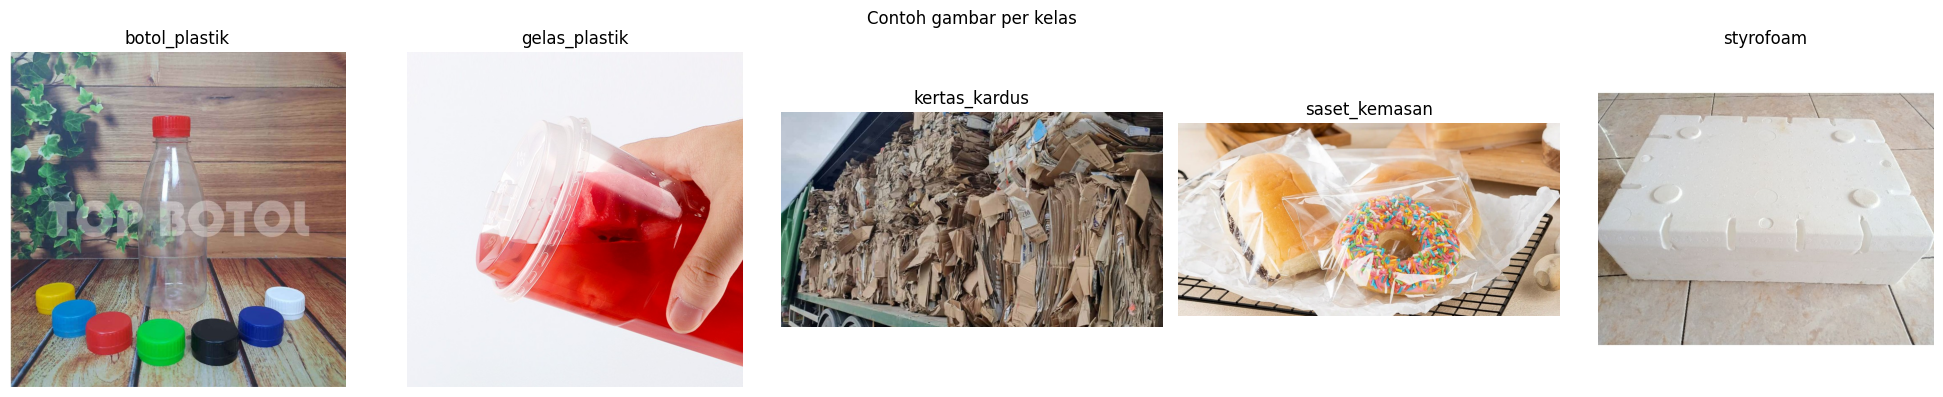

In [9]:
# Visualisasi contoh gambar tiap kelas
fig, axes = plt.subplots(1, num_classes, figsize=(4*num_classes, 4))
axes = np.atleast_1d(axes)
for ax, cls in zip(axes, unique_labels):
    p = next(p for p, l in samples if l == cls)
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis('off')
plt.suptitle('Contoh gambar per kelas')
plt.tight_layout()
plt.show()

## 6. Membangun dan Melatih Model

### Arsitektur Model
1. **Model Dasar**: EfficientNet-B3 pre-trained dari ImageNet
2. **Classifier Kustom**:
   - Fitur input: 1536 (dimensi fitur EfficientNet-B3)
   - Layer tersembunyi: 1024 unit dengan ReLU + BatchNorm
   - Layer dropout (0.3 dan 0.2) untuk regularisasi
   - Layer output: 5 kelas sampah

### Pelatihan
- Loss: CrossEntropyLoss, optimizer: AdamW, scheduler: CosineAnnealingLR
- Model terbaik (akurasi validasi tertinggi) disimpan ke `best_model_sampah.pth`
- Jika checkpoint sudah ada dan `RETRAIN = False`, pelatihan dilewati dan checkpoint dimuat

In [10]:
print("Building EfficientNet-B3 (pre-trained ImageNet)...")
weights = EfficientNet_B3_Weights.IMAGENET1K_V1
model = efficientnet_b3(weights=weights)

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3, inplace=True),
    nn.Linear(1536, 1024),
    nn.ReLU(),
    nn.BatchNorm1d(1024),
    nn.Dropout(p=0.2),
    nn.Linear(1024, num_classes)
)
model = model.to(device)
print(f"Classifier diganti dengan output {num_classes} kelas.")

Building EfficientNet-B3 (pre-trained ImageNet)...
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 151MB/s]


Classifier diganti dengan output 5 kelas.


In [11]:
CKPT_PATH = 'best_model_sampah.pth'
RETRAIN = True   # False = muat checkpoint jika sudah ada

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

if os.path.exists(CKPT_PATH) and not RETRAIN:
    checkpoint = torch.load(CKPT_PATH, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    best_val_acc = checkpoint['best_val_acc']
    print(f"Checkpoint dimuat. Best val acc: {best_val_acc:.2f}%")
else:
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}  (lr={optimizer.param_groups[0]['lr']:.6f})")
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, label_to_idx)
        va_loss, va_acc = validate(model, val_loader, criterion, device, label_to_idx)
        scheduler.step()

        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss);   history['val_acc'].append(va_acc)
        print(f"Train loss {tr_loss:.4f} acc {tr_acc:.2f}% | Val loss {va_loss:.4f} acc {va_acc:.2f}%")

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_val_acc': best_val_acc,
                'label_to_idx': label_to_idx,
            }, CKPT_PATH)
            print(f"  -> Model terbaik disimpan ({best_val_acc:.2f}%)")

    # muat kembali model terbaik untuk evaluasi
    checkpoint = torch.load(CKPT_PATH, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])

model.eval()
print(f"\nBest validation accuracy: {best_val_acc:.2f}%")


Epoch 1/15  (lr=0.001000)


Validation: 100%|██████████| 18/18 [00:09<00:00,  1.81it/s, loss=0.32, acc=90.6]


Train loss 0.5768 acc 80.56% | Val loss 0.3196 acc 90.56%
  -> Model terbaik disimpan (90.56%)

Epoch 2/15  (lr=0.000989)


Validation: 100%|██████████| 18/18 [00:06<00:00,  2.63it/s, loss=0.22, acc=91.8]


Train loss 0.2572 acc 91.60% | Val loss 0.2196 acc 91.83%
  -> Model terbaik disimpan (91.83%)

Epoch 3/15  (lr=0.000957)


...

Train loss 0.0081 acc 99.77% | Val loss 0.2027 acc 94.74%
  -> Model terbaik disimpan (94.74%)

Epoch 14/15  (lr=0.000043)


Validation: 100%|██████████| 18/18 [00:07<00:00,  2.54it/s, loss=0.209, acc=94]


Train loss 0.0152 acc 99.55% | Val loss 0.2088 acc 94.01%

Epoch 15/15  (lr=0.000011)


Validation: 100%|██████████| 18/18 [00:07<00:00,  2.47it/s, loss=0.2, acc=94.7]


Train loss 0.0133 acc 99.64% | Val loss 0.1997 acc 94.74%

Best validation accuracy: 94.74%


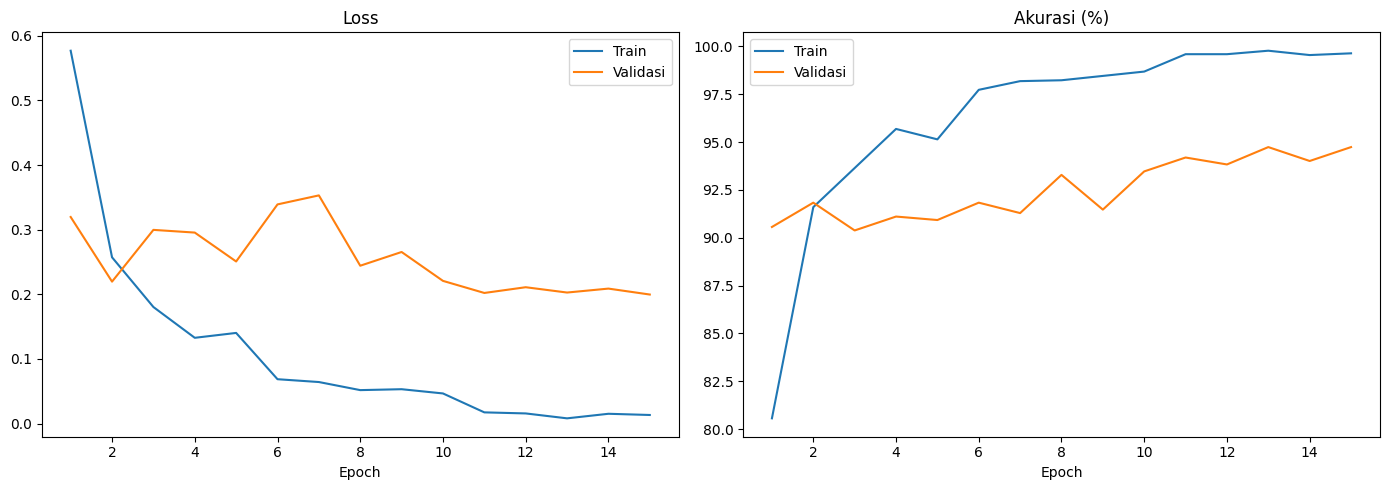

In [12]:
# Kurva loss dan akurasi (hanya jika pelatihan dijalankan pada sesi ini)
if len(history['train_loss']) > 0:
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_range, history['train_loss'], label='Train')
    ax[0].plot(epochs_range, history['val_loss'], label='Validasi')
    ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(epochs_range, history['train_acc'], label='Train')
    ax[1].plot(epochs_range, history['val_acc'], label='Validasi')
    ax[1].set_title('Akurasi (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout()
    plt.show()

### Ringkasan Arsitektur Model

Berikut ringkasan detail arsitektur model: jumlah parameter per layer, ukuran output di setiap layer, total parameter, dan estimasi memori.

In [13]:
# Tampilkan ringkasan model menggunakan torchinfo
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

input_size = (batch_size, 3, 300, 300)

model_summary = summary(model,
                      input_size=input_size,
                      col_names=["input_size", "output_size", "num_params", "kernel_size", "mult_adds"],
                      col_width=20,
                      row_settings=["var_names"])

print("\nStatistik Parameter Model:")
print(f"Total Parameters: {model_summary.total_params:,}")
print(f"Trainable Parameters: {model_summary.trainable_params:,}")
print(f"Non-trainable Parameters: {model_summary.total_params - model_summary.trainable_params:,}")
print(f"Estimasi Ukuran Model: {model_summary.total_params * 4 / (1024*1024):.2f} MB")


Statistik Parameter Model:
Total Parameters: 12,277,293
Trainable Parameters: 12,277,293
Non-trainable Parameters: 0
Estimasi Ukuran Model: 46.83 MB


## 7. Evaluasi Model

Model dievaluasi pada data validasi (20% dari `train_sources.csv`) dengan beberapa metrik:

1. **Confusion Matrix**: prediksi vs label sebenarnya, membantu melihat kelas yang sering tertukar
2. **Classification Report**: precision, recall, F1-score, dan support per kelas
3. **Kurva ROC dan AUC**: kemampuan model membedakan antar kelas (one-vs-rest)
4. **Visualisasi prediksi**: contoh prediksi benar dan salah

Getting model predictions on validation data...


Evaluating: 100%|██████████| 18/18 [00:07<00:00,  2.57it/s]



EVALUATION RESULTS
Total samples: 551
Correct predictions: 522
Wrong predictions: 29
Accuracy: 94.74%


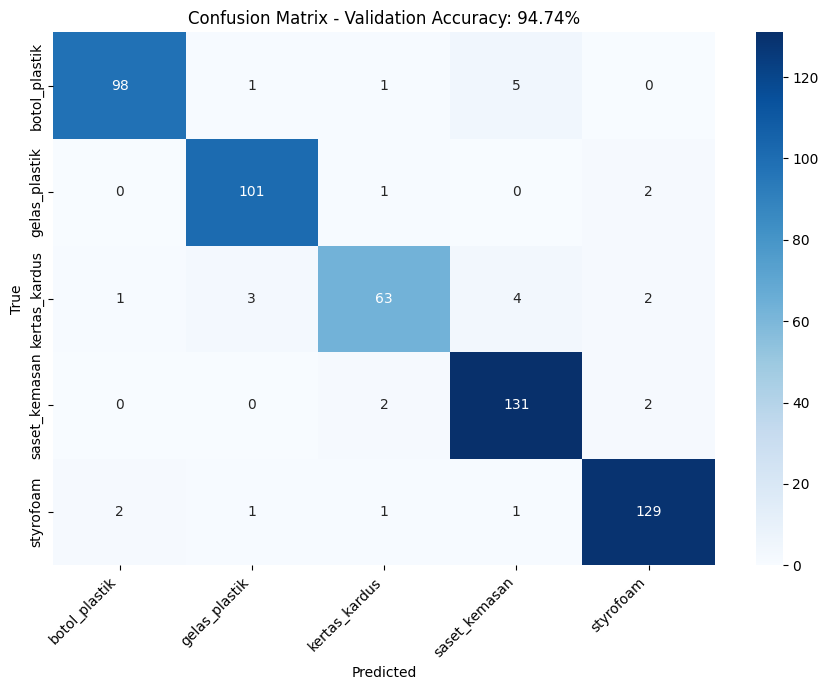


Detailed Classification Report:
--------------------------------------------------------------------------------
               precision    recall  f1-score   support

botol_plastik       0.97      0.93      0.95       105
gelas_plastik       0.95      0.97      0.96       104
kertas_kardus       0.93      0.86      0.89        73
saset_kemasan       0.93      0.97      0.95       135
    styrofoam       0.96      0.96      0.96       134

     accuracy                           0.95       551
    macro avg       0.95      0.94      0.94       551
 weighted avg       0.95      0.95      0.95       551

Detailed results saved to 'detailed_val_results.csv'


In [14]:
def evaluate_model(model, dataloader, device, label_to_idx, idx_to_label):
    model.eval()
    all_preds, all_labels, all_probs, all_filenames = [], [], [], []
    correct_predictions, wrong_predictions = [], []

    with torch.no_grad():
        for inputs, labels_tuple, filenames in tqdm(dataloader, desc='Evaluating'):
            inputs = inputs.to(device)

            label_indices = [label_to_idx[label] for label in labels_tuple]
            targets = torch.tensor(label_indices, dtype=torch.long)

            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            batch_preds = preds.cpu().numpy()
            batch_targets = targets.cpu().numpy()
            batch_probs = probs.cpu().numpy()

            all_preds.extend(batch_preds)
            all_labels.extend(batch_targets)
            all_probs.extend(batch_probs)
            all_filenames.extend(filenames)

            for i in range(len(batch_preds)):
                item = {
                    'filename': filenames[i],
                    'predicted': idx_to_label[batch_preds[i]],
                    'actual': idx_to_label[batch_targets[i]]
                }
                if batch_preds[i] == batch_targets[i]:
                    correct_predictions.append(item)
                else:
                    wrong_predictions.append(item)

    return (np.array(all_preds), np.array(all_labels), np.array(all_probs),
            all_filenames, correct_predictions, wrong_predictions)

print("Getting model predictions on validation data...")
(val_preds, val_labels, val_probs, val_filenames,
 correct_preds, wrong_preds) = evaluate_model(model, val_loader, device, label_to_idx, idx_to_label)

total_samples = len(val_labels)
correct_count = len(correct_preds)
wrong_count = len(wrong_preds)
accuracy = (correct_count / total_samples) * 100

print(f"\n{'='*50}")
print("EVALUATION RESULTS")
print(f"{'='*50}")
print(f"Total samples: {total_samples}")
print(f"Correct predictions: {correct_count}")
print(f"Wrong predictions: {wrong_count}")
print(f"Accuracy: {accuracy:.2f}%")
print(f"{'='*50}")

class_names = [idx_to_label[i] for i in range(len(idx_to_label))]

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Validation Accuracy: {accuracy:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Classification report
print("\nDetailed Classification Report:")
print("-" * 80)
print(classification_report(val_labels, val_preds, target_names=class_names))

# Simpan hasil
results_df = pd.DataFrame({
    'filename': val_filenames,
    'predicted': [idx_to_label[p] for p in val_preds],
    'actual': [idx_to_label[l] for l in val_labels],
    'correct': [p == l for p, l in zip(val_preds, val_labels)]
})
results_df.to_csv('detailed_val_results.csv', index=False)
print("Detailed results saved to 'detailed_val_results.csv'")

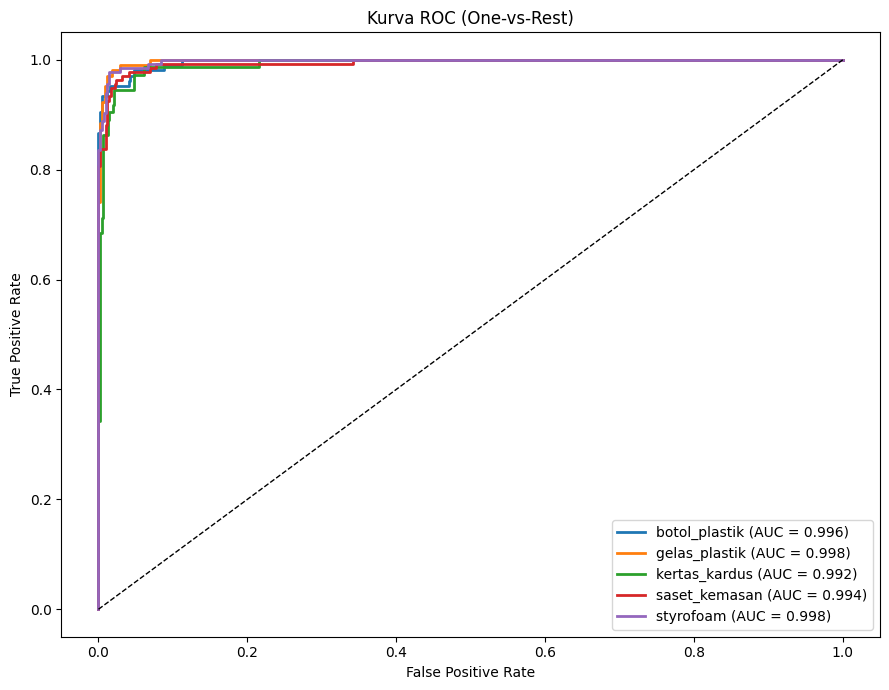

In [15]:
# Kurva ROC (one-vs-rest) dan AUC per kelas
y_bin = label_binarize(val_labels, classes=list(range(num_classes)))

plt.figure(figsize=(9, 7))
colors = cycle(['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown'])
for i, color in zip(range(num_classes), colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], val_probs[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Visualizing sample predictions...


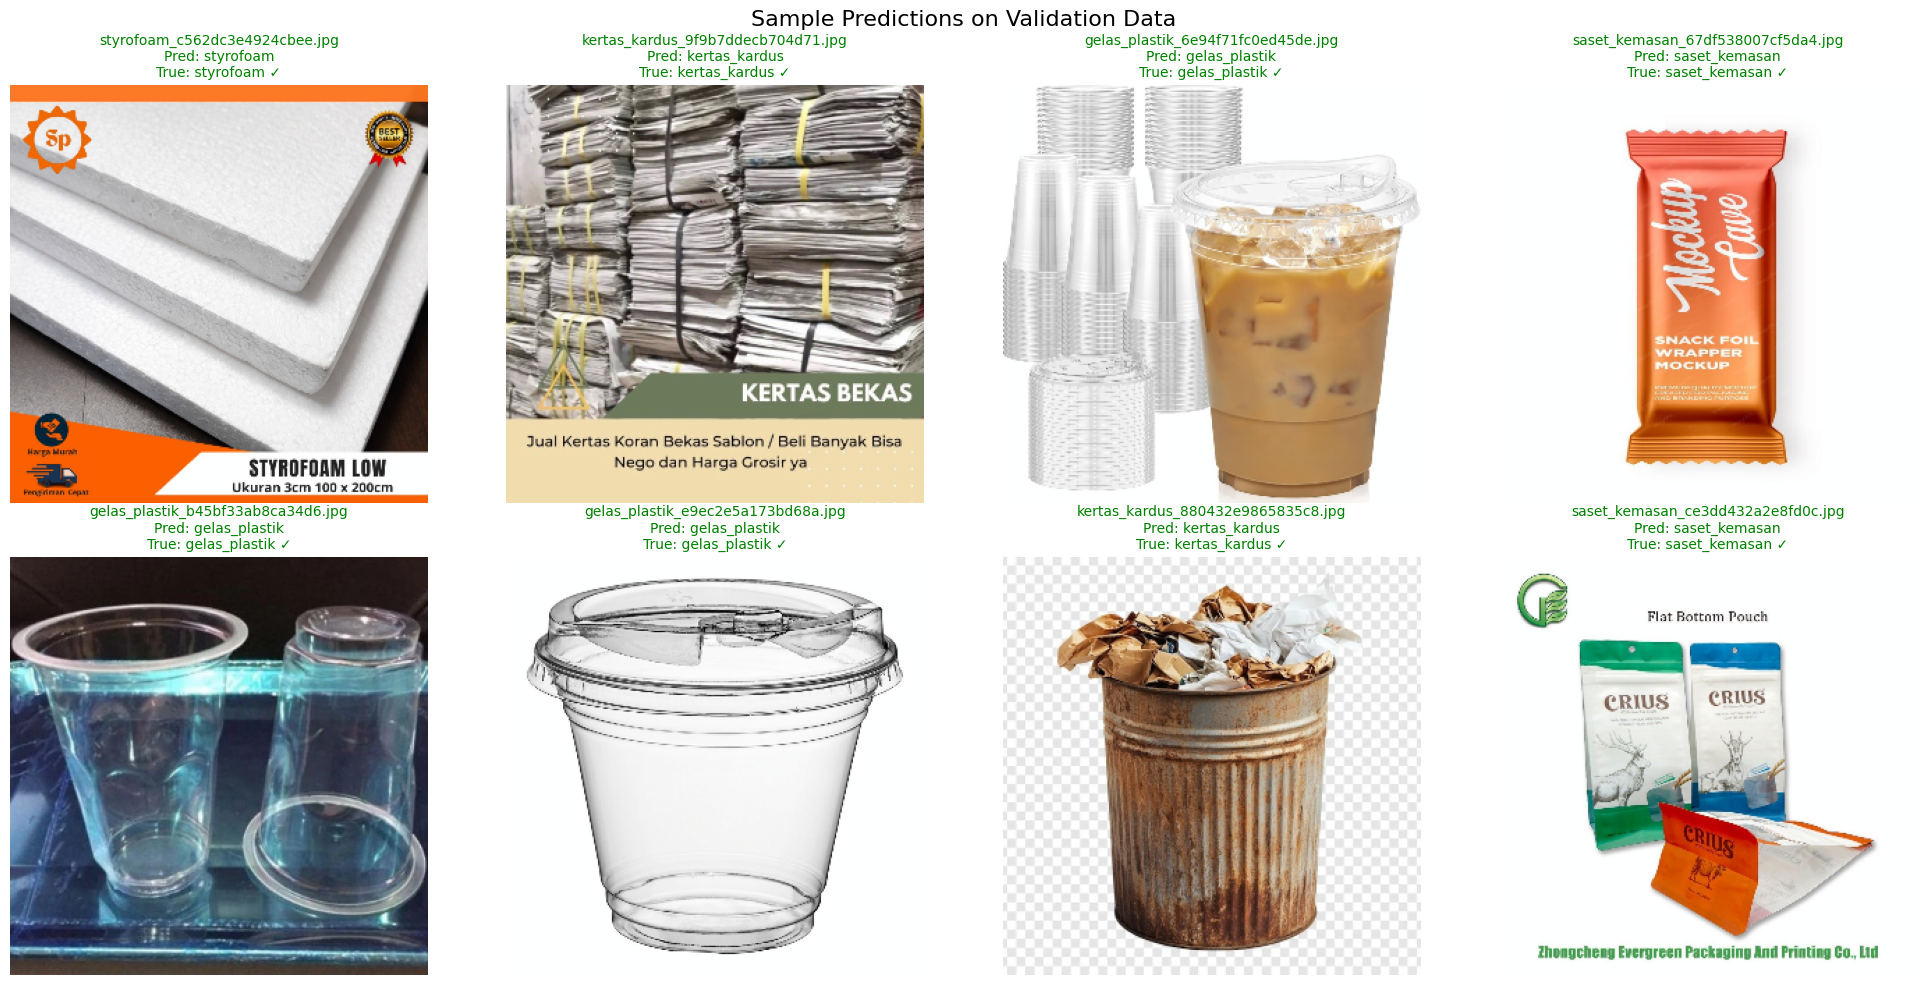


DETAILED PREDICTION EXAMPLES

EXAMPLES OF CORRECT PREDICTIONS:
--------------------------------------------------
1. File: styrofoam_c562dc3e4924cbee.jpg | Predicted: styrofoam       | Actual: styrofoam       ✓
2. File: kertas_kardus_9f9b7ddecb704d71.jpg | Predicted: kertas_kardus   | Actual: kertas_kardus   ✓
3. File: gelas_plastik_6e94f71fc0ed45de.jpg | Predicted: gelas_plastik   | Actual: gelas_plastik   ✓
4. File: saset_kemasan_67df538007cf5da4.jpg | Predicted: saset_kemasan   | Actual: saset_kemasan   ✓
5. File: gelas_plastik_b45bf33ab8ca34d6.jpg | Predicted: gelas_plastik   | Actual: gelas_plastik   ✓

EXAMPLES OF WRONG PREDICTIONS:
------------------------------------------------------------
1. File: styrofoam_fac36e7e4d911a87.jpg | Predicted: botol_plastik   | Actual: styrofoam       ✗
2. File: botol_plastik_e077a55ea42cceed.jpg | Predicted: saset_kemasan   | Actual: botol_plastik   ✗
3. File: saset_kemasan_950d30a780d1fd71.jpg | Predicted: styrofoam       | Actual: saset_kema

In [16]:
# Visualisasi prediksi pada data validasi
def show_predictions(model, dataloader, device, idx_to_label, num_images=8):
    model.eval()
    images_shown = 0

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.ravel()

    with torch.no_grad():
        for inputs, labels, filenames in dataloader:
            if images_shown >= num_images:
                break

            outputs = model(inputs.to(device))
            _, preds = torch.max(outputs, 1)

            batch_images = inputs.cpu().numpy()
            batch_preds = preds.cpu().numpy()

            for i in range(len(batch_images)):
                if images_shown >= num_images:
                    break

                pred_label = idx_to_label[batch_preds[i]]
                true_label = labels[i]
                filename = os.path.basename(filenames[i])

                # Denormalize image for display
                img = batch_images[i].transpose(1, 2, 0)
                img = img * np.array(DatasetSampah.IMAGENET_STD) + np.array(DatasetSampah.IMAGENET_MEAN)
                img = np.clip(img, 0, 1)

                axes[images_shown].imshow(img)

                is_correct = pred_label == true_label
                color = 'green' if is_correct else 'red'
                status = '✓' if is_correct else '✗'
                axes[images_shown].set_title(f'{filename}\nPred: {pred_label}\nTrue: {true_label} {status}',
                                             color=color, fontsize=10)
                axes[images_shown].axis('off')
                images_shown += 1

    for i in range(images_shown, len(axes)):
        axes[i].axis('off')

    plt.suptitle('Sample Predictions on Validation Data', fontsize=16, y=0.98)
    plt.tight_layout()
    plt.show()

print("Visualizing sample predictions...")
show_predictions(model, val_loader, device, idx_to_label)

print(f"\n{'='*80}")
print("DETAILED PREDICTION EXAMPLES")
print(f"{'='*80}")

if len(correct_preds) > 0:
    print("\nEXAMPLES OF CORRECT PREDICTIONS:")
    print("-" * 50)
    for i, pred in enumerate(correct_preds[:5]):
        print(f"{i+1}. File: {os.path.basename(pred['filename']):20} | Predicted: {pred['predicted']:15} | Actual: {pred['actual']:15} ✓")

if len(wrong_preds) > 0:
    print("\nEXAMPLES OF WRONG PREDICTIONS:")
    print("-" * 60)
    for i, pred in enumerate(wrong_preds[:5]):
        print(f"{i+1}. File: {os.path.basename(pred['filename']):20} | Predicted: {pred['predicted']:15} | Actual: {pred['actual']:15} ✗")

print(f"\n{'='*80}")
print("FINAL SUMMARY")
print(f"{'='*80}")
print(f"Dataset: {TRAIN_DIR} dengan label dari {os.path.basename(CSV_PATH)}")
print(f"Model: {CKPT_PATH} (EfficientNet-B3)")
print(f"Total validation samples: {total_samples}")
print(f"Correct predictions: {correct_count}")
print(f"Wrong predictions: {wrong_count}")
print(f"Validation Accuracy: {accuracy:.2f}%")
print(f"{'='*80}")